# 2. Two-site population dynamics

**Thesis:** Aditya Banerjee, *Linear Anyon Model with Rydberg Atoms*, Universitat de Barcelona (2026). [Read the thesis](https://hdl.handle.net/2445/231684).

**Reading guide:** Sections 3.6 and 3.8–3.8.1, pp. 20–25; Figure 3. Page numbers below are the printed thesis pages. Equations retain the thesis notation and numbering; an extract from a longer equation is identified as an extract.

**Evidence:** the physics text describes the theoretical model and numerical calculations reported in the thesis. It does not add experimental results or new derivations. Calculation cells come from the original uploaded scripts at commit `22959963191fcbc4d283ec4b272b506ad6dd979b`. Short setup cells only handle notebook execution and display.

Read each explanation, then run its code cell. Source discrepancies and notebook adaptations are labelled explicitly.

**Notebook setup / execution control:** Imports used by the scripts; locate the repository data directory and display plots inline.

In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product
from timeit import default_timer as timer
import numpy as np
from scipy.special import jv
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'scripts').is_dir() and (p / 'data').is_dir())
DATA = ROOT / 'data'

## 1. Parameters and basis

**Thesis source:** Figure 3, p. 25. Explanations below paraphrase this passage.

Figure 3 uses the six initial configurations displayed by the script. The basis labels below enumerate the nine two-site occupation states.

**Symbols — Table 1, Section 3.3, and Figure 3.**

| Thesis symbol | Meaning | Script name |
|---|---|---|
| $C_{ij}$ | Interaction-shift parameters | `C00`, `C01`, … |
| $\Omega_\alpha,\Omega_\beta$ | Coupling amplitudes | `Om_a`, `Om_b` |
| $\omega'$ | Modulation frequency | `WP` or `wp` |
| $A$ | Modulation amplitude | `A` |
| $\kappa=A/\omega'$ | Modulation index | `kap` or `kappa` |
| $\widetilde\nu_j$ | Floquet detuning at site $j$ | `nu`, `nt0`, `nt1` |
| $J_\ell(\kappa)$ | Bessel function of order $\ell$ | `jv(ells, ...)` |
| $L$, $N$ | Number of sites; total occupation | `L`, `N` |

**Source convention:** the thesis and original scripts label these numerical energies/rates in MHz and use $\hbar=1$ for evolution. Their original labels and numbers are retained here. **Source discrepancy:** the `heff2_states.py` header equates MHz with rad/µs, whereas thesis Appendix B writes $\omega'/(2\pi)=40$ MHz. This notebook reproduces the supplied convention; it does not resolve that frequency conversion or introduce a replacement time variable.

**Code source:** [`heff2_states.py`, lines 28–64](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_states.py#L28-L64).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [2]:
hbar = 1.0
C00, C01, C11 = 0.0, 20.0, 15.0
C02 = 2.0 * C11                      # 2 C11 = C02  ->  30
C12, C22 = 45.0, 55.0
_C = {(0,0):C00,(0,1):C01,(1,1):C11,(0,2):C02,(1,2):C12,(2,2):C22}
def C(i, j): return _C[(min(i,j), max(i,j))]

Om_a  = 1.0                          # realistic Rb Rabi frequencies (MHz)
Om_b  = 1.0
alpha = np.pi/4                      # alpha-drive phase
beta  = np.pi/3                      # beta-drive phase
# Put the Floquet 3-level block {02,11,20} on exact resonance by setting the
# two-photon Floquet detuning to compensate its differential AC-Stark shift
# (E_11 -> E_20).  A standard experimental knob; nu_tilde is adjusted slightly
# off the bare integer to absorb the Stark shift.
COMPENSATE_11BLOCK = True

wp = 40.0                            # omega'  (large -> well-separated sidebands)
A  = 48.0
kappa = A / wp                       # 1.2
# nu_tilde_0 = nu_tilde_1 makes the exchange {01,10} and cross-site {12,21}
# blocks EXACTLY resonant (E_01=E_10, E_12=E_21, E_02=E_20 automatically),
# and gives N0=N1=1 (both Floquet channels on), q=0.  Nearest sideband 10 MHz.
nt0, nt1 = -40.0, -40.0

LMAX = 40
ells = np.arange(-LMAX, LMAX + 1)
Jl   = jv(ells, kappa)

N0 = (2*C11 - C02 - nt0)/wp
N1 = (2*C11 - C02 - nt1)/wp
q  = (nt1 - nt0)/wp
def is_int(x, tol=1e-9): return abs(x - round(x)) < tol

labels = ['00','01','02','10','11','12','20','21','22']
idx = {s:i for i,s in enumerate(labels)}
DIM = 9

**Source discrepancy:** comments in the uploaded script describe detuning retuning; the executed code below only adds `delta_comp` to `E["11"]`. Its original numerical operation is retained, without asserting that a microscopic retuning was calculated.

## 2. AC Stark diagonal

**Thesis source:** Section 3.6, p. 20, Eqs. (41)–(42). Explanations below paraphrase this passage.

Equation (42) gives the nine diagonal entries using the sums defined in Eq. (41). The code first evaluates those entries, then applies the uploaded compensation operation.

**Code source:** [`heff2_states.py`, lines 69–73](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_states.py#L69-L73).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [3]:
def stark_sum(dconst, nu):
    denom = dconst + nu + ells*wp
    if np.any(np.abs(denom) < 1e-9):
        raise ZeroDivisionError(f"resonant Stark denominator (dconst={dconst}, nu={nu})")
    return np.sum(Jl**2 / denom)

**Code source:** [`heff2_states.py`, lines 75–89](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_states.py#L75-L89).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [4]:
E = {}
E['00'] = -2*Om_a**2/(C01-2*C00)
E['01'] = ( Om_a**2/(C01-2*C00) - Om_a**2/(2*C11-C01)
          - Om_b**2*stark_sum(C02-C01, nt1) )
E['02'] = ( Om_b**2*stark_sum(C02-C01, nt1) - Om_a**2/(C12-C02) )
E['10'] = ( Om_a**2/(C01-2*C00) - Om_a**2/(2*C11-C01)
          - Om_b**2*stark_sum(C02-C01, nt0) )
E['11'] = ( 2*Om_a**2/(2*C11-C01)
          - Om_b**2*stark_sum(C12-2*C11, nt0) - Om_b**2*stark_sum(C12-2*C11, nt1) )
E['12'] = ( Om_a**2/(C12-C02) + Om_b**2*stark_sum(C12-2*C11, nt1)
          - Om_b**2*stark_sum(2*C22-C12, nt0) )
E['20'] = ( Om_b**2*stark_sum(C02-C01, nt0) - Om_a**2/(C12-C02) )
E['21'] = ( Om_a**2/(C12-C02) + Om_b**2*stark_sum(C12-2*C11, nt0)
          - Om_b**2*stark_sum(2*C22-C12, nt1) )
E['22'] = ( Om_b**2*stark_sum(2*C22-C12, nt0) + Om_b**2*stark_sum(2*C22-C12, nt1) )

**Code source:** [`heff2_states.py`, lines 92–93](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_states.py#L92-L93).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [5]:
delta_comp = (E['20'] - E['11']) if COMPENSATE_11BLOCK else 0.0
E['11'] += delta_comp

## 3. Exchange matrix

**Thesis source:** Section 3.6, p. 21, Eqs. (43)–(44). Explanations below paraphrase this passage.

The four processes of Eq. (43) connect the occupation states. The integer conditions in Eq. (44) determine whether the Floquet-assisted terms survive. `add_coupling` inserts each forward and reverse matrix element.

**Code source:** [`heff2_states.py`, lines 98–119](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_states.py#L98-L119).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [6]:
H = np.zeros((DIM, DIM), dtype=complex)
for s in labels: H[idx[s], idx[s]] = E[s]
def add_coupling(bra, ket, amp):
    H[idx[bra], idx[ket]] += amp
    H[idx[ket], idx[bra]] += np.conj(amp)

g1 = Om_a**2*(1.0/(C01-2*C00) - 1.0/(2*C11-C01))            # |01><->|10>
add_coupling('10', '01', g1*np.exp(-1j*alpha))

pref = Om_a*Om_b*(1.0/(2*C11-C01) - 1.0/(C12-C02))
g2 = pref*jv(round(N0), kappa) if is_int(N0) else 0.0       # |11><->|20>
if g2: add_coupling('20', '11', g2*np.exp(1j*(beta-2*alpha)))
g3 = pref*jv(round(N1), kappa) if is_int(N1) else 0.0       # |02><->|11>
if g3: add_coupling('11', '02', g3*np.exp(1j*(alpha-2*beta)))
if is_int(q):                                               # |12><->|21>
    qi = round(q)
    Sig = (1.0/(C12-2*C11+nt0+ells*wp) - 1.0/(2*C22-C12+nt0+ells*wp))
    g4 = Om_b**2*np.sum(Jl*jv(ells-qi, kappa)*Sig)
    add_coupling('21', '12', g4*np.exp(-1j*beta))
else:
    g4 = 0.0
assert np.allclose(H, H.conj().T)

## 4. Time evolution

**Thesis source:** Section 3.8, p. 23, Eq. (48). Explanations below paraphrase this passage.

The thesis evolves the initial state as
$$|\psi(t)\rangle=e^{-iH_{\mathrm{eff}}^{(2)}t}|\psi(0)\rangle.\tag{48}$$
Here $|\psi(0)\rangle$ is the initial occupation state. Section 3.8 interprets these curves as stroboscopic evolution: the separate micromotion within a driving period is not included.

**Code reading:** `np.linalg.eigh(H)` obtains eigenvalues and eigenvectors. `evolve` projects the initial state into that basis, applies the time-dependent phases, and returns the occupation-state probabilities. `ket` builds the selected initial state.

**Code source:** [`heff2_states.py`, lines 124–132](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_states.py#L124-L132).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [7]:
evals, evecs = np.linalg.eigh(H)
def evolve(psi0, t):
    c = evecs.conj().T @ psi0
    return np.abs((np.exp(-1j*np.outer(t, evals)/hbar)*c) @ evecs.T)**2
def ket(s):
    v = np.zeros(DIM, dtype=complex); v[idx[s]] = 1.0; return v
def two_level(Ea, Eb, g):
    d = 0.5*(Ea-Eb); Om = np.hypot(abs(g), d)
    return (abs(g)**2/(abs(g)**2+d**2) if Om>0 else 0.0), (np.pi/Om if Om>0 else np.inf)

## 5. Analytic interpretation in the thesis

**Thesis source:** Section 3.8.1, pp. 24–25, Eqs. (49)–(55). Explanations below paraphrase this passage.

The $N=1$ and $N=3$ manifolds are two-state exchange blocks. For $01\leftrightarrow10$, the thesis gives
$$V_{01,10}=\Omega_\alpha^2\left(\frac{1}{C_{01}-2C_{00}}-\frac{1}{2C_{11}-C_{01}}\right),\tag{49}$$
$$P_{10}(t)=\frac{4V_{01,10}^{2}}{\Delta_{01,10}^{2}+4V_{01,10}^{2}}
\sin^2\!\left(\frac{t}{2}\sqrt{\Delta_{01,10}^{2}+4V_{01,10}^{2}}\right),\qquad P_{01}(t)=1-P_{10}(t).\tag{50}$$
$V_{01,10}$ is the exchange coupling; $\Delta_{01,10}$ is the difference of the two diagonal shifts, written explicitly in Eq. (51). Equation (52) describes the $12\leftrightarrow21$ block.

For the $N=2$ manifold, $|11\rangle$ couples to both $|02\rangle$ and $|20\rangle$. Under the exact-resonance assumption of Eqs. (54)–(55),
$$\Omega_{\mathrm{eff}}=|\Omega_\alpha\Omega_\beta|
\left|\frac{1}{2C_{11}-C_{01}}-\frac{1}{C_{12}-C_{02}}\right|
\sqrt{J_{N_0}^2(\kappa)+J_{N_1}^2(\kappa)},\tag{54}$$
$$P_{11}(t)=\cos^2(\Omega_{\mathrm{eff}}t),\quad
P_{02}(t)=\frac{J_{N_1}^2(\kappa)}{J_{N_0}^2(\kappa)+J_{N_1}^2(\kappa)}\sin^2(\Omega_{\mathrm{eff}}t),\quad
P_{20}(t)=\frac{J_{N_0}^2(\kappa)}{J_{N_0}^2(\kappa)+J_{N_1}^2(\kappa)}\sin^2(\Omega_{\mathrm{eff}}t).\tag{55}$$
The code below uses the uploaded `two_level` function to set each plotting window. The full populations are calculated by `evolve`, not by a newly introduced analytic solver.

**Code source:** [`heff2_states.py`, lines 152–154](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_states.py#L152-L154).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [8]:
p_ex,T_ex = two_level(E['01'],E['10'],g1)
p_f, T_f  = two_level(E['11'],E['20'],g2)
p_cs,T_cs = two_level(E['12'],E['21'],g4)

## 6. Plot the six initial configurations

**Thesis source:** Figure 3, p. 25. Explanations below paraphrase this passage.

Figure 3 shows two-level exchange in the $N=1$ and $N=3$ blocks, the three-state dynamics in $N=2$, and the stationary uncoupled $|22angle$ state. The following plot uses the original six panels and 5000 samples per panel.

**Code source:** [`heff2_states.py`, lines 165–221](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_states.py#L165-L221).

**Notebook changes:** Original plot and numerical sampling; inline display replaces the image export. Time labels reproduce the source convention described above.

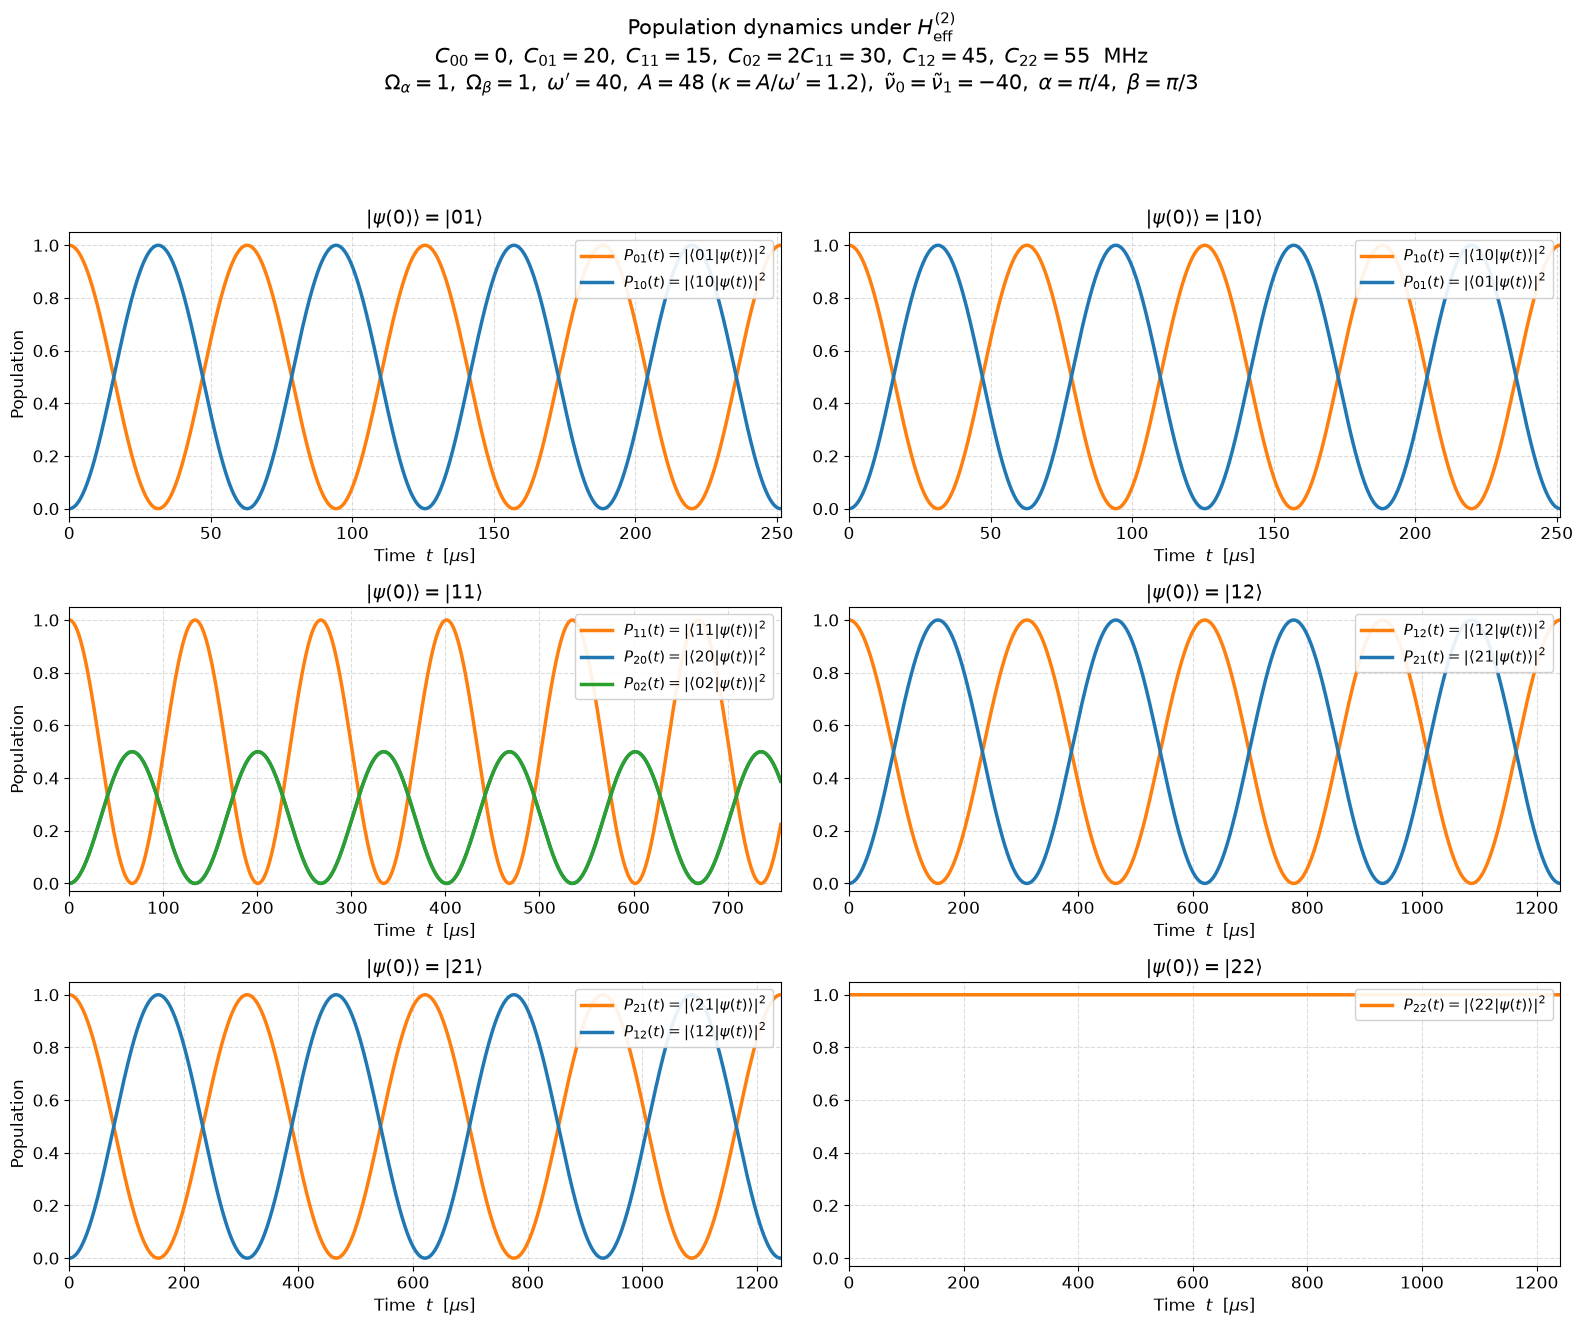

In [9]:
plt.rcParams.update({'font.size': 12})

# per-panel palette in the reference style: initial state orange, partners blue/green
PALETTE = ['tab:orange', 'tab:blue', 'tab:green']

# (initial state, states to display, time window)
panels = [
    ('01', ['01','10'],            4*T_ex),
    ('10', ['10','01'],            4*T_ex),
    ('11', ['11','20','02'],       4*T_f),
    ('12', ['12','21'],            4*T_cs),
    ('21', ['21','12'],            4*T_cs),
    ('22', ['22'],                 4*T_cs),
]

fig, axes = plt.subplots(3, 2, figsize=(16, 13.5))
for k, (ax, (init, watch, tmax)) in enumerate(zip(axes.ravel(), panels)):
    tt = np.linspace(0, tmax, 5000)
    pops = evolve(ket(init), tt)
    for s, col in zip(watch, PALETTE):
        ax.plot(tt, pops[:, idx[s]], color=col, lw=2.5,
                label=rf'$P_{{{s}}}(t) = |\langle {s}|\psi(t)\rangle|^2$')
    ax.set_title(rf'$|\psi(0)\rangle = |{init}\rangle$', fontsize=14)
    ax.set_xlabel(r'Time  $t$  [$\mu$s]')
    if k % 2 == 0:
        ax.set_ylabel('Population')
    ax.set_xlim(0, tmax); ax.set_ylim(-0.03, 1.05)
    ax.legend(loc='upper right', fontsize=11, framealpha=0.9)
    ax.grid(True, ls='--', alpha=0.45)

from fractions import Fraction
def pi_str(x):
    """Render x as a nice multiple of pi (e.g. pi/3), else as a decimal."""
    if abs(x) < 1e-12:
        return "0"
    fr = Fraction(x / np.pi).limit_denominator(24)
    if abs(float(fr) * np.pi - x) > 1e-9:
        return f"{x:.3g}"
    n, d = fr.numerator, fr.denominator
    sign = "-" if n < 0 else ""
    num = r"\pi" if abs(n) == 1 else rf"{abs(n)}\pi"
    return f"{sign}{num}" if d == 1 else f"{sign}{num}/{d}"

sup = (r'Population dynamics under $H_{\mathrm{eff}}^{(2)}$'
       + '\n'
       + r'$C_{00}=%g,\; C_{01}=%g,\; C_{11}=%g,\; C_{02}=2C_{11}=%g,\; '
         r'C_{12}=%g,\; C_{22}=%g$  MHz'
         % (C00, C01, C11, C02, C12, C22)
       + '\n'
       + r"$\Omega_\alpha=%g,\; \Omega_\beta=%g,\; \omega'=%g,\; A=%g\;"
         r"(\kappa=A/\omega'=%g),\; \tilde{\nu}_0=\tilde{\nu}_1=%g,\; "
         r"\alpha=%s,\; \beta=%s$"
         % (Om_a, Om_b, wp, A, kappa, nt0, pi_str(alpha), pi_str(beta)))
fig.suptitle(sup, fontsize=15)
fig.tight_layout(rect=[0, 0, 1, 0.925])
plt.show()

## Source and reproduction record

The original scripts and saved data are unchanged. See [SOURCE_MAP.md](SOURCE_MAP.md) for the thesis-to-code map and [VALIDATION.md](VALIDATION.md) for the checks performed on this revision.